In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-python.tar.gz
/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py/batches.meta
/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py/data_batch_1
/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py/data_batch_2
/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py/data_batch_3
/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py/data_batch_4
/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py/data_batch_5
/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py/readme.html
/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py/test_batch


In [2]:
import os, pickle, random, time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


## Загрузка данных

In [3]:
DATA_DIR = '/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py'

def load_batch(path):
    with open(path, 'rb') as f:
        d = pickle.load(f, encoding='bytes')
    x = d[b'data'].reshape(-1, 3, 32, 32)
    y = np.array(d[b'labels'])
    return x, y

parts = [load_batch(f'{DATA_DIR}/data_batch_{i}') for i in range(1, 6)]
X_train = np.concatenate([p[0] for p in parts])
y_train = np.concatenate([p[1] for p in parts])
X_test, y_test = load_batch(f'{DATA_DIR}/test_batch')

with open(f'{DATA_DIR}/batches.meta', 'rb') as f:
    class_names = [n.decode() for n in pickle.load(f, encoding='bytes')[b'label_names']]

print('X_train:', X_train.shape, X_train.dtype)
print('y_train:', y_train.shape)
print('X_test:', X_test.shape)
print('y_test:', y_test.shape)
print('Форма одного изображения:', X_train[0].shape, '(каналы, высота, ширина)')
print('Классы:', class_names)

X_train: (50000, 3, 32, 32) uint8
y_train: (50000,)
X_test: (10000, 3, 32, 32)
y_test: (10000,)
Форма одного изображения: (3, 32, 32) (каналы, высота, ширина)
Классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


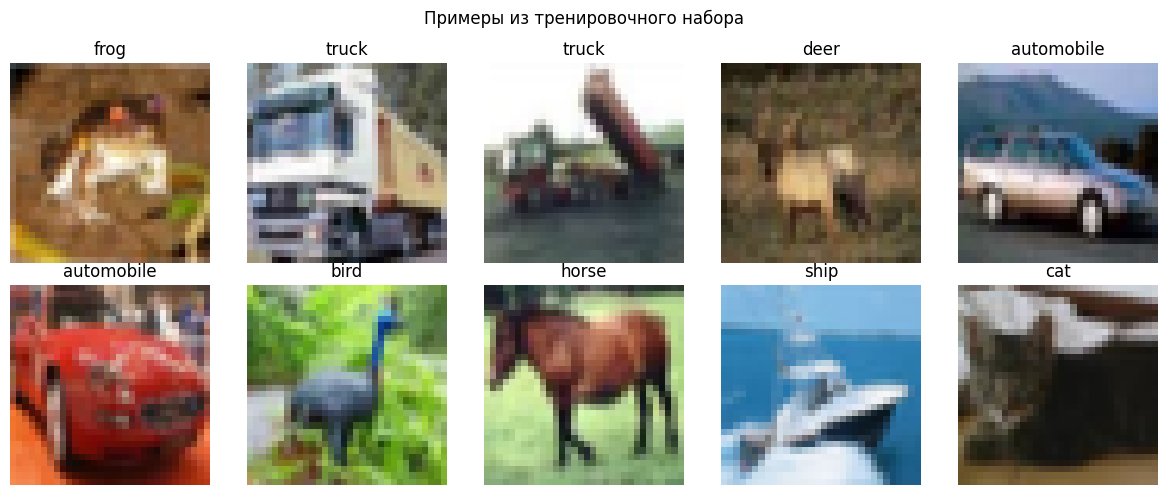

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.ravel()):
    img = X_train[i].transpose(1, 2, 0)
    ax.imshow(img)
    ax.set_title(class_names[y_train[i]])
    ax.axis('off')
plt.suptitle('Примеры из тренировочного набора')
plt.tight_layout()
plt.show()

## Предобработка данных

In [5]:
X_float = X_train.astype(np.float32) / 255.0
mean = X_float.mean(axis=(0, 2, 3))
std  = X_float.std(axis=(0, 2, 3))

train_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.Normalize(mean, std),
])
test_tf = transforms.Compose([
    transforms.Normalize(mean, std),
])

class CIFARDataset(Dataset):
    def __init__(self, x, y, transform=None):
        self.x = torch.from_numpy(x)
        self.y = torch.from_numpy(y).long()
        self.transform = transform
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        img = self.x[i].float() / 255.0  # масштабируем в [0, 1]
        if self.transform:
            img = self.transform(img)
        return img, self.y[i]

BATCH_SIZE = 128

train_loader = DataLoader(CIFARDataset(X_train, y_train, train_tf), batch_size=BATCH_SIZE, 
                          shuffle=True, num_workers=2, pin_memory=True, drop_last=True)
test_loader  = DataLoader(CIFARDataset(X_test, y_test, test_tf), batch_size=256, 
                          shuffle=False, num_workers=2, pin_memory=True)

In [6]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),
        )
    def forward(self, x):
        return self.block(x)


class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10, dropout=0.4):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3, 64),  # 3x32x32   -> 64x16x16
            ConvBlock(64, 128),  # 64x16x16  -> 128x8x8
            ConvBlock(128, 256),  # 128x8x8   -> 256x4x4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 512),  # 256*4*4 = 4096
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = SimpleCNN().to(device)
print(model)
print('Параметров:', sum(p.numel() for p in model.parameters()))

SimpleCNN(
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(

In [7]:
EPOCHS = 30
MAX_LR = 0.1
WEIGHT_DECAY = 5e-4
MOMENTUM = 0.9

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=MAX_LR, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)

steps_per_epoch = len(train_loader)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=MAX_LR, epochs=EPOCHS, steps_per_epoch=steps_per_epoch
)

In [8]:
def train_one_epoch(model, loader):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        scheduler.step()

        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        out = model(x)
        total_loss += criterion(out, y).item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return total_loss / n, correct / n

In [9]:
history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()

    tr_loss, tr_acc = train_one_epoch(model, train_loader)
    te_loss, te_acc = evaluate(model, test_loader)

    history['train_loss'].append(tr_loss)
    history['train_acc'].append(tr_acc)
    history['test_loss'].append(te_loss)
    history['test_acc'].append(te_acc)

    lr_now = optimizer.param_groups[0]['lr']
    print(f'Эпоха {epoch:2d}/{EPOCHS} | '
          f'train loss: {tr_loss:.4f}, acc: {tr_acc*100:.2f}% | '
          f'test loss: {te_loss:.4f}, acc: {te_acc*100:.2f}% | '
          f'lr: {lr_now:.4f} | {time.time()-t0:.1f}s')

Эпоха  1/30 | train loss: 1.3550, acc: 50.77% | test loss: 1.0377, acc: 63.33% | lr: 0.0069 | 18.7s
Эпоха  2/30 | train loss: 0.9610, acc: 66.14% | test loss: 0.9576, acc: 68.69% | lr: 0.0152 | 11.2s
Эпоха  3/30 | train loss: 0.8333, acc: 70.86% | test loss: 0.8018, acc: 72.35% | lr: 0.0280 | 11.3s
Эпоха  4/30 | train loss: 0.7207, acc: 75.04% | test loss: 0.6339, acc: 77.91% | lr: 0.0437 | 11.7s
Эпоха  5/30 | train loss: 0.6397, acc: 77.91% | test loss: 0.6387, acc: 77.37% | lr: 0.0604 | 12.0s
Эпоха  6/30 | train loss: 0.5737, acc: 80.14% | test loss: 0.6794, acc: 76.90% | lr: 0.0760 | 12.8s
Эпоха  7/30 | train loss: 0.5238, acc: 81.83% | test loss: 0.5749, acc: 80.62% | lr: 0.0888 | 13.3s
Эпоха  8/30 | train loss: 0.4859, acc: 83.22% | test loss: 0.5936, acc: 79.98% | lr: 0.0971 | 13.8s
Эпоха  9/30 | train loss: 0.4539, acc: 84.34% | test loss: 0.4750, acc: 83.51% | lr: 0.1000 | 13.3s
Эпоха 10/30 | train loss: 0.4286, acc: 85.31% | test loss: 0.5596, acc: 81.43% | lr: 0.0994 | 12.8s


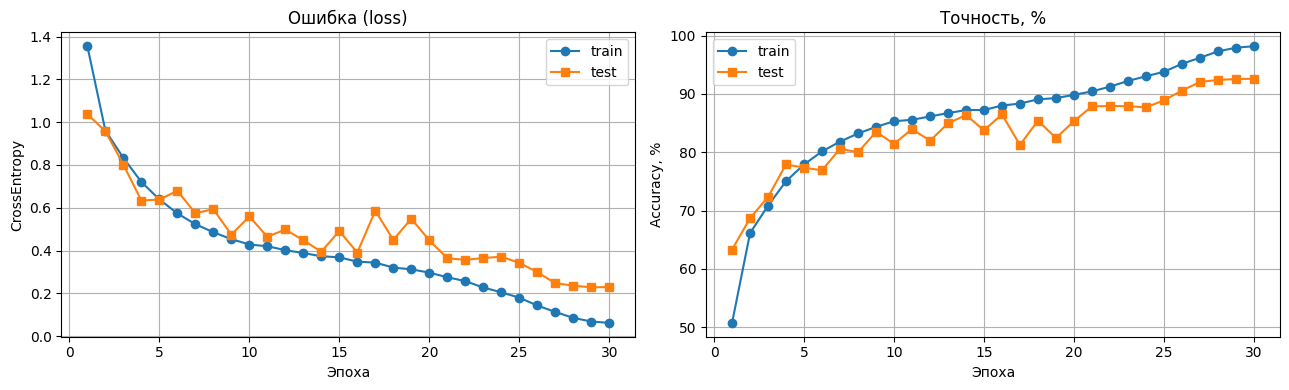

In [10]:
epochs_range = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(epochs_range, history['train_loss'], marker='o', label='train')
ax[0].plot(epochs_range, history['test_loss'],  marker='s', label='test')
ax[0].set_title('Ошибка (loss)')
ax[0].set_xlabel('Эпоха'); ax[0].set_ylabel('CrossEntropy'); ax[0].grid(True); ax[0].legend()

ax[1].plot(epochs_range, [a * 100 for a in history['train_acc']], marker='o', label='train')
ax[1].plot(epochs_range, [a * 100 for a in history['test_acc']],  marker='s', label='test')
ax[1].set_title('Точность, %')
ax[1].set_xlabel('Эпоха'); ax[1].set_ylabel('Accuracy, %'); ax[1].grid(True); ax[1].legend()

plt.tight_layout(); plt.show()

In [11]:
test_loss, test_acc = evaluate(model, test_loader)
print(f'TEST | loss: {test_loss:.4f} | accuracy: {test_acc*100:.2f}% | ошибка классификации: {(1-test_acc)*100:.2f}%')

TEST | loss: 0.2300 | accuracy: 92.58% | ошибка классификации: 7.42%


In [12]:
@torch.no_grad()
def per_class_accuracy(model, loader):
    model.eval()
    correct = np.zeros(10); total = np.zeros(10)
    for x, y in loader:
        pred = model(x.to(device)).argmax(1).cpu()
        for c in range(10):
            mask = (y == c)
            total[c] += mask.sum().item()
            correct[c] += (pred[mask] == c).sum().item()
    return correct / total

for name, acc in zip(class_names, per_class_accuracy(model, test_loader)):
    print(f'{name:12s} {acc*100:.1f}%')

airplane     94.2%
automobile   97.2%
bird         88.4%
cat          82.9%
deer         94.0%
dog          90.2%
frog         94.4%
horse        93.7%
ship         95.9%
truck        94.9%
